# Phase 3B Steps 1–2 — Statistical Foundations and Sampling Distributions

## Customer Retention Intelligence System

This independent notebook builds the inferential-statistics foundation for later
telecom churn analysis. It uses only the configured development split. It does
**not** perform formal hypothesis tests on IBM Telco data, estimate confidence
intervals, select features, fit preprocessing, balance classes, or train a model.

The IBM dataset is a static observational snapshot with an unknown sampling
mechanism. Resampling below treats development data as an empirical distribution
for mathematical education; it does not prove broader telecom representativeness.

## 1. Independent, leakage-safe setup

The project root is detected dynamically. The input must be exactly the configured
`data/processed/development.parquet`. Previous notebooks are neither imported nor
executed. The configured seed controls every simulation.

In [1]:
# ruff: noqa: E501
import importlib.metadata as metadata
import sys
from pathlib import Path


def find_project_root(start: Path) -> Path:
    """Return the nearest parent containing project marker files."""
    start = start.resolve()
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").is_file() and (candidate / "params.yaml").is_file():
            return candidate
    raise FileNotFoundError("Could not locate project root.")


PROJECT_ROOT = find_project_root(Path.cwd())
SRC_PATH = PROJECT_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

from retention.utils.config import load_config  # noqa: E402

config = load_config(PROJECT_ROOT / "params.yaml")
configured_development_path = Path(config["data"]["development_path"])
assert configured_development_path == Path("data/processed/development.parquet")
development_path = (PROJECT_ROOT / configured_development_path).resolve()
assert development_path.is_file()

print(f"Project root: {PROJECT_ROOT}")
print(f"Input: {configured_development_path}")
print(f"Python: {sys.version.split()[0]} ({sys.executable})")
for package in ["numpy", "pandas", "scipy", "matplotlib", "seaborn", "pyarrow"]:
    print(f"{package}: {metadata.version(package)}")

Project root: /Users/harshagarwal/Projects/ChurnRatePredictor
Input: data/processed/development.parquet
Python: 3.11.14 (/Users/harshagarwal/Projects/ChurnRatePredictor/.venv/bin/python)
numpy: 2.4.6
pandas: 2.3.3
scipy: 1.17.1
matplotlib: 3.11.2
seaborn: 0.13.2
pyarrow: 26.0.1


In [2]:
# ruff: noqa: E501
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 200)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.labelsize": 11})

random_state = int(config["project"]["random_state"])
target_column = config["data"]["target_column"]
identifier_column = config["data"]["id_column"]
source_sha256_before = hashlib.sha256(development_path.read_bytes()).hexdigest()
df = pd.read_parquet(development_path)
rng = np.random.default_rng(random_state)

assert df.shape == (5_634, 21)
assert set(df[target_column].unique()) == {"No", "Yes"}
print(f"Development data: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Random state: {random_state}")
print(f"Development SHA-256: {source_sha256_before}")
display(df.head())

Development data: 5,634 rows × 21 columns
Random state: 42
Development SHA-256: 28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,5334-JLAXU,Female,0,Yes,No,60,Yes,Yes,Fiber optic,Yes,Yes,No,No,No,Yes,Month-to-month,Yes,Credit card (automatic),94.100000,"5,475.900000",No
1,4573-JKNAE,Male,0,No,Yes,12,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.350000,212.300000,No
2,6923-JHPMP,Female,0,No,No,2,Yes,No,Fiber optic,Yes,No,Yes,No,No,No,Month-to-month,Yes,Electronic check,80.450000,137.100000,No
3,5524-KHNJP,Male,0,Yes,Yes,33,Yes,No,DSL,Yes,No,Yes,No,Yes,Yes,One year,No,Credit card (automatic),74.750000,"2,453.300000",No
4,5433-KYGHE,Female,0,No,Yes,14,Yes,Yes,Fiber optic,Yes,No,No,Yes,No,No,Month-to-month,Yes,Mailed check,86.000000,"1,164.050000",No


# 2. Inferential-statistics fundamentals

**Descriptive statistics** summarize observed records. **Inferential statistics**
quantify uncertainty when a sample is used to reason about an underlying population
or data-generating process.

A population parameter is fixed but usually unknown:

$$\mu=\mathbb{E}[X],\qquad p=P(Y=1).$$

A sample statistic varies across samples:

$$\bar X=\frac{1}{n}\sum_{i=1}^{n}X_i,\qquad
\hat p=\frac{1}{n}\sum_{i=1}^{n}Y_i.$$

The observed development churn rate is a **statistic**. Calling it a population
churn probability requires assumptions about sampling, time stability, mix, and
measurement.

| Concept | Definition and intuition | Assumption or risk | Misconception | ML relevance |
|---|---|---|---|---|
| Population vs sample | Population is the target universe; sample is observed subset. | Define market, geography, product, and time. | Large means representative. | Deployment depends on training–target alignment. |
| Parameter vs statistic | Parameter describes population; statistic estimates it. | Estimator and sampling determine uncertainty. | Sample mean equals population mean. | Metrics are variable statistics. |
| Representativeness | Relevant groups/mechanisms appear appropriately. | Inclusion mechanism must be understood. | Stratified splitting fixes source bias. | Internal splits cannot repair source bias. |
| Sampling variability | Repeated samples yield different statistics by chance. | Requires a sampling model. | Different estimates imply coding error. | CV/bootstrap estimates also vary. |
| Sampling bias | Inclusion systematically shifts estimates. | Selection probabilities should be ignorable/known. | More rows eliminate bias. | Big biased data remain biased. |
| Selection bias | Inclusion relates to exposure, outcome, or both. | Missing customer types distort associations. | Random splitting eliminates it. | Models learn distorted relationships. |
| IID | Independent observations from one distribution. | Households, regions, and time may violate IID. | Unique IDs guarantee independence. | Dependence makes validation/SE optimistic. |
| Uncertainty | Lack of precision from finite noisy data. | Inherits model assumptions. | A point estimate is complete evidence. | Decisions need uncertainty, not ranks alone. |

The IBM file has no documented probability-sampling design. Resampling here is
conditional on its empirical distribution—not evidence about the wider market.

## Estimation, testing, exploration, and confirmation

- **Estimation** asks about magnitude. Point estimates and later confidence
  intervals address effect size and precision.
- **Hypothesis testing** asks whether data are sufficiently incompatible with a
  specified null model.
- **Exploratory inference** develops questions after seeing patterns and is exposed
  to data-dependent selection and multiplicity.
- **Confirmatory inference** pre-specifies questions, outcomes, analysis, and error
  control before examining confirmatory data.

Every project hypothesis below was informed by EDA on this development split. The
register is exploratory, not independent confirmation. Stronger confirmation would
use a pre-registered analysis on new or genuinely untouched observations.

**Practical checklist:** define the target population and estimand; document
selection; assess independence, measurement and missingness; distinguish
pre-specified from data-informed questions; report magnitude and uncertainty; and
never convert predictive association into causal language.

# 3. Hypothesis formulation

The **null hypothesis** $H_0$ is a reference claim, often no association or no
difference. The **alternative** $H_1$ represents departures of interest. A
two-sided alternative, $H_1:\mu_1-\mu_0\ne0$, permits either direction. A one-sided
alternative requires independent directional justification.

A **test statistic** compresses the data into a quantity with a known or
approximated null distribution. A p-value is

$$P(\text{statistic at least as incompatible with }H_0\mid H_0,
\text{ assumptions}).$$

It is not $P(H_0\mid\text{data})$. At significance level $\alpha$, reject when
$p\le\alpha$; otherwise **fail to reject**. Failure to reject does not prove
equality.

- **Type I error:** reject true $H_0$; controlled at $\alpha$ under valid assumptions.
- **Type II error:** fail to reject false $H_0$; probability $\beta$.
- **Power:** $1-\beta$ for a specified alternative.
- **Statistical significance:** incompatibility with a null relative to a threshold.
- **Practical significance:** whether magnitude matters after value, cost, risk,
  uncertainty, and feasibility.

A tiny charge difference can be statistically significant at huge $n$ yet be
commercially irrelevant. Conversely, an important effect may be imprecise in a
small group. Later work must report effect size and uncertainty with any p-value.

**Assumptions:** valid sampling, suitable model, reliable measurement, independence
or dependence-aware methods, and multiplicity control. **ML relevance:** these
ideas prevent overclaiming small metric improvements found after repeated searches.

# 4. Project-specific exploratory hypothesis register

The register converts EDA findings into explicit questions without calculating a
telecom test statistic or p-value. Two-sided alternatives are preferred because
directions were observed rather than independently pre-registered.

In [3]:
# ruff: noqa: E501
register_columns = [
    "hypothesis_id", "business_question", "predictor", "outcome", "variable_types",
    "null_hypothesis", "alternative_hypothesis", "candidate_test", "assumptions",
    "effect_size", "potential_confounders", "business_relevance", "multiple_testing_family",
]
hypotheses = [
    ["HYP-01", "Does tenure differ by churn outcome?", "Churn", "tenure", "binary categorical → discrete numerical", "Population tenure means/distributions are equal across churn groups.", "They differ (two-sided).", "Welch t-test for means; Mann–Whitney sensitivity", "Independent customers, finite variance, reliable tenure", "Hedges' g plus raw/quantile differences", "Contract, services, acquisition cohort", "Lifecycle retention planning", "Numerical predictors vs churn"],
    ["HYP-02", "Do MonthlyCharges differ by churn outcome?", "Churn", "MonthlyCharges", "binary categorical → continuous numerical", "Population means are equal.", "Population means differ (two-sided).", "Welch two-sample t-test", "Independent customers, finite variance, meaningful scale", "Raw mean difference and Hedges' g", "Internet service, add-ons, contract, tenure", "Pricing exposure and product mix", "Numerical predictors vs churn"],
    ["HYP-03", "Do TotalCharges differ by churn outcome?", "Churn", "TotalCharges", "binary categorical → skewed continuous numerical", "Population means/distributions are equal.", "They differ (two-sided).", "Welch test; robust/permutation sensitivity later", "Independent customers, finite variance, zero-tenure handling", "Raw mean, Hedges' g, quantile differences", "Tenure, MonthlyCharges, contract", "Accumulated exposure diagnosis", "Numerical predictors vs churn"],
    ["HYP-04", "Is contract type associated with churn?", "Contract", "Churn", "3-level categorical × binary", "Contract and churn are independent.", "They are associated (omnibus).", "Chi-square independence test", "Independent customers, adequate expected counts", "Bias-corrected Cramér's V and rate differences", "Tenure, service mix, payment", "Commitment strategy", "Categorical service/billing vs churn"],
    ["HYP-05", "Is internet service type associated with churn?", "InternetService", "Churn", "3-level categorical × binary", "InternetService and churn are independent.", "They are associated (omnibus).", "Chi-square independence test", "Independent customers, adequate counts, structural levels retained", "Bias-corrected Cramér's V and risk differences", "Charges, add-ons, contract, tenure", "Product experience", "Categorical service/billing vs churn"],
    ["HYP-06", "Is payment method associated with churn?", "PaymentMethod", "Churn", "4-level categorical × binary", "PaymentMethod and churn are independent.", "They are associated (omnibus).", "Chi-square independence test", "Independent customers, adequate expected counts", "Bias-corrected Cramér's V", "Paperless billing, contract, demographics, tenure", "Payment-friction diagnosis", "Categorical service/billing vs churn"],
    ["HYP-07", "Is technical-support status associated with churn?", "TechSupport", "Churn", "3-level categorical × binary", "TechSupport and churn are independent.", "They are associated (omnibus).", "Chi-square independence test", "Independent customers, structural no-internet level retained", "Bias-corrected Cramér's V and rate differences", "InternetService, contract, tenure, charges", "Support adoption", "Categorical service/billing vs churn"],
    ["HYP-08", "Is online-security status associated with churn?", "OnlineSecurity", "Churn", "3-level categorical × binary", "OnlineSecurity and churn are independent.", "They are associated (omnibus).", "Chi-square independence test", "Independent customers, structural no-internet level retained", "Bias-corrected Cramér's V and rate differences", "InternetService, TechSupport, contract, charges", "Security bundle analysis", "Categorical service/billing vs churn"],
    ["HYP-09", "Is paperless billing associated with churn?", "PaperlessBilling", "Churn", "binary categorical × binary", "PaperlessBilling and churn are independent.", "They are associated (two-sided).", "Chi-square / two-proportion test", "Independent customers, adequate counts", "Phi coefficient and absolute risk difference", "PaymentMethod, age, contract, tenure", "Billing-channel experience", "Categorical service/billing vs churn"],
    ["HYP-10", "Are demographic attributes associated with churn?", "gender, SeniorCitizen, Partner, Dependents", "Churn", "four binary categorical predictors × binary", "Each demographic attribute is independent of churn within the family.", "At least one is associated (two-sided family).", "Separate chi-square/two-proportion tests with multiplicity control", "Independent customers, pre-specified family, adequate counts", "Phi and absolute risk differences", "Tenure, contract, services, household structure", "Fairness monitoring, not targeting", "Demographics vs churn"],
]
hypothesis_register = pd.DataFrame(hypotheses, columns=register_columns)
assert len(hypothesis_register) == 10
assert hypothesis_register["hypothesis_id"].is_unique
assert hypothesis_register.notna().all().all()
display(hypothesis_register)

,hypothesis_id,business_question,predictor,outcome,variable_types,null_hypothesis,alternative_hypothesis,candidate_test,assumptions,effect_size,potential_confounders,business_relevance,multiple_testing_family
0,HYP-01,Does tenure differ by churn outcome?,Churn,tenure,binary categorical → discrete numerical,Population tenure means/distributions are equa...,They differ (two-sided).,Welch t-test for means; Mann–Whitney sensitivity,"Independent customers, finite variance, reliab...",Hedges' g plus raw/quantile differences,"Contract, services, acquisition cohort",Lifecycle retention planning,Numerical predictors vs churn
1,HYP-02,Do MonthlyCharges differ by churn outcome?,Churn,MonthlyCharges,binary categorical → continuous numerical,Population means are equal.,Population means differ (two-sided).,Welch two-sample t-test,"Independent customers, finite variance, meanin...",Raw mean difference and Hedges' g,"Internet service, add-ons, contract, tenure",Pricing exposure and product mix,Numerical predictors vs churn
2,HYP-03,Do TotalCharges differ by churn outcome?,Churn,TotalCharges,binary categorical → skewed continuous numerical,Population means/distributions are equal.,They differ (two-sided).,Welch test; robust/permutation sensitivity later,"Independent customers, finite variance, zero-t...","Raw mean, Hedges' g, quantile differences","Tenure, MonthlyCharges, contract",Accumulated exposure diagnosis,Numerical predictors vs churn
3,HYP-04,Is contract type associated with churn?,Contract,Churn,3-level categorical × binary,Contract and churn are independent.,They are associated (omnibus).,Chi-square independence test,"Independent customers, adequate expected counts",Bias-corrected Cramér's V and rate differences,"Tenure, service mix, payment",Commitment strategy,Categorical service/billing vs churn
4,HYP-05,Is internet service type associated with churn?,InternetService,Churn,3-level categorical × binary,InternetService and churn are independent.,They are associated (omnibus).,Chi-square independence test,"Independent customers, adequate counts, struct...",Bias-corrected Cramér's V and risk differences,"Charges, add-ons, contract, tenure",Product experience,Categorical service/billing vs churn
5,HYP-06,Is payment method associated with churn?,PaymentMethod,Churn,4-level categorical × binary,PaymentMethod and churn are independent.,They are associated (omnibus).,Chi-square independence test,"Independent customers, adequate expected counts",Bias-corrected Cramér's V,"Paperless billing, contract, demographics, tenure",Payment-friction diagnosis,Categorical service/billing vs churn
6,HYP-07,Is technical-support status associated with ch...,TechSupport,Churn,3-level categorical × binary,TechSupport and churn are independent.,They are associated (omnibus).,Chi-square independence test,"Independent customers, structural no-internet ...",Bias-corrected Cramér's V and rate differences,"InternetService, contract, tenure, charges",Support adoption,Categorical service/billing vs churn
7,HYP-08,Is online-security status associated with churn?,OnlineSecurity,Churn,3-level categorical × binary,OnlineSecurity and churn are independent.,They are associated (omnibus).,Chi-square independence test,"Independent customers, structural no-internet ...",Bias-corrected Cramér's V and rate differences,"InternetService, TechSupport, contract, charges",Security bundle analysis,Categorical service/billing vs churn
8,HYP-09,Is paperless billing associated with churn?,PaperlessBilling,Churn,binary categorical × binary,PaperlessBilling and churn are independent.,They are associated (two-sided).,Chi-square / two-proportion test,"Independent customers, adequate counts",Phi coefficient and absolute risk difference,"PaymentMethod, age, contract, tenure",Billing-channel experience,Categorical service/billing vs churn
9,HYP-10,Are demographic attributes associated with churn?,"gender, SeniorCitizen, Partner, Dependents",Churn,four binary categorical predictors × binary,E

### Register safeguards

Candidate tests are not decisions. Later work must define estimands, inspect cell
support and dependence, choose multiplicity control, and report effect sizes with
uncertainty. These questions are EDA-informed, so tests on the same records remain
exploratory. Demographics support fairness assessment, not discriminatory targeting.
Contract, tenure, services, and charges are interrelated, making unadjusted results
vulnerable to confounding; causal claims are not justified.

# 5. Synthetic Type I/Type II error and power demonstration

Synthetic individual outcomes have known standard deviation $\sigma=1$. For a
sample mean of size $n$ with standardized effect $\delta$,

$$\bar X\sim N\left(\delta,\frac{\sigma}{\sqrt n}\right).$$

A two-sided Z test evaluates $H_0:\delta=0$ at $\alpha=0.05$ and rejects when
$|Z|>z_{1-\alpha/2}$. This is a controlled mathematical experiment—not a telecom
finding. Normality, known variance, independence, and effect magnitudes are
simulation assumptions.

In [4]:
# ruff: noqa: E501
alpha = 0.05
sigma = 1.0
simulation_repetitions = 100_000
z_critical = stats.norm.ppf(1 - alpha / 2)
sample_sizes = np.array([10, 30, 50, 100, 500])
effect_sizes = np.array([0.0, 0.2, 0.5, 0.8])
power_rows = []
for n in sample_sizes:
    standard_error = sigma / np.sqrt(n)
    for effect in effect_sizes:
        simulated_means = rng.normal(effect, standard_error, simulation_repetitions)
        rejection_rate = np.mean(np.abs(simulated_means / standard_error) > z_critical)
        noncentrality = effect / standard_error
        theoretical_power = stats.norm.cdf(-z_critical - noncentrality) + 1 - stats.norm.cdf(z_critical - noncentrality)
        power_rows.append({"sample_size": int(n), "standardized_effect": float(effect), "simulated_rejection_rate": rejection_rate, "theoretical_power": theoretical_power, "absolute_difference": abs(rejection_rate - theoretical_power)})
power_results = pd.DataFrame(power_rows)
false_positive_rate = power_results.query("standardized_effect == 0")["simulated_rejection_rate"].mean()
print(f"Mean simulated Type I error: {false_positive_rate:.4f} (target={alpha:.2f})")
display(power_results)

Mean simulated Type I error: 0.0503 (target=0.05)


,sample_size,standardized_effect,simulated_rejection_rate,theoretical_power,absolute_difference
0,10,0.000000,0.050900,0.050000,0.000900
1,10,0.200000,0.097920,0.096935,0.000985
2,10,0.500000,0.352210,0.352608,0.000398
3,10,0.800000,0.717590,0.715617,0.001973
4,30,0.000000,0.049960,0.050000,0.000040
5,30,0.200000,0.193410,0.194775,0.001365
6,30,0.500000,0.783330,0.781908,0.001422
7,30,0.800000,0.992410,0.992278,0.000132
8,50,0.000000,0.050320,0.050000,0.000320
9,50,0.200000,0.294800,0.292989,0.001811


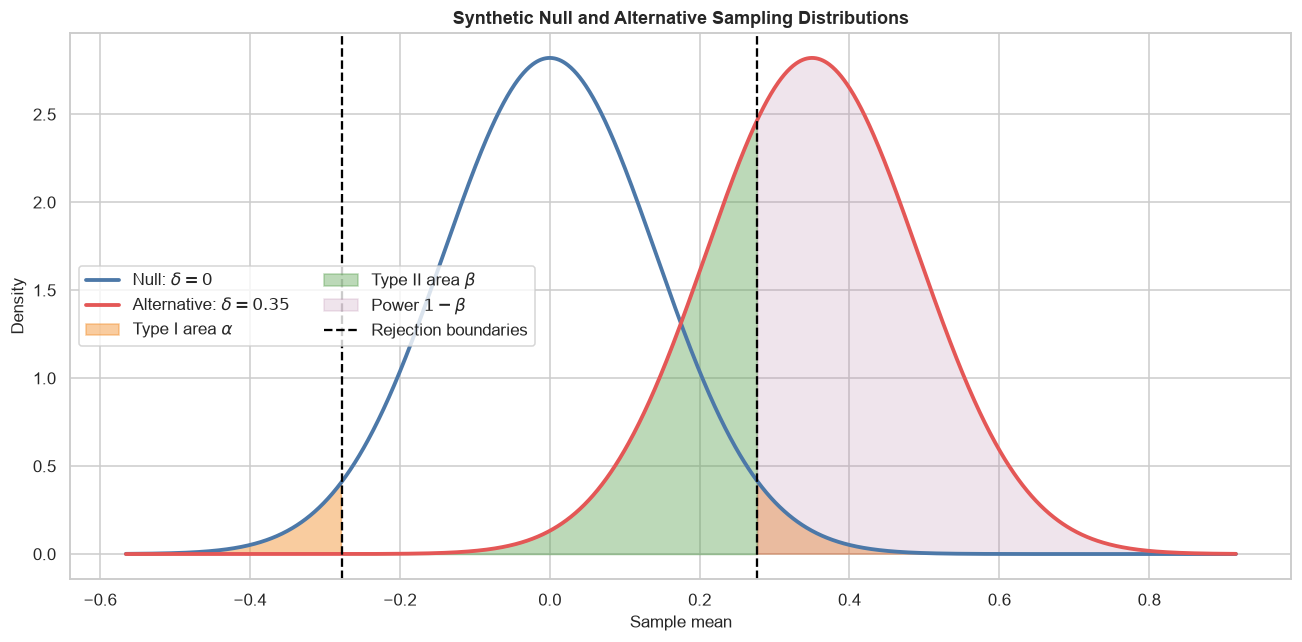

In [5]:
# ruff: noqa: E501
reference_n, reference_effect = 50, 0.35
reference_se = sigma / np.sqrt(reference_n)
critical_mean = z_critical * reference_se
x = np.linspace(-4 * reference_se, reference_effect + 4 * reference_se, 1_500)
null_pdf = stats.norm.pdf(x, 0, reference_se)
alternative_pdf = stats.norm.pdf(x, reference_effect, reference_se)
acceptance = (x >= -critical_mean) & (x <= critical_mean)
rejection = ~acceptance
fig, axis = plt.subplots(figsize=(12, 6))
axis.plot(x, null_pdf, label=r"Null: $\delta=0$", color="#4C78A8", linewidth=2.5)
axis.plot(x, alternative_pdf, label=rf"Alternative: $\delta={reference_effect}$", color="#E45756", linewidth=2.5)
axis.fill_between(x, 0, null_pdf, where=rejection, color="#F28E2B", alpha=0.45, label=r"Type I area $\alpha$")
axis.fill_between(x, 0, alternative_pdf, where=acceptance, color="#59A14F", alpha=0.40, label=r"Type II area $\beta$")
axis.fill_between(x, 0, alternative_pdf, where=rejection, color="#B279A2", alpha=0.20, label=r"Power $1-\beta$")
axis.axvline(-critical_mean, color="black", linestyle="--")
axis.axvline(critical_mean, color="black", linestyle="--", label="Rejection boundaries")
axis.set(title="Synthetic Null and Alternative Sampling Distributions", xlabel="Sample mean", ylabel="Density")
axis.legend(ncol=2)
plt.tight_layout()
plt.show()

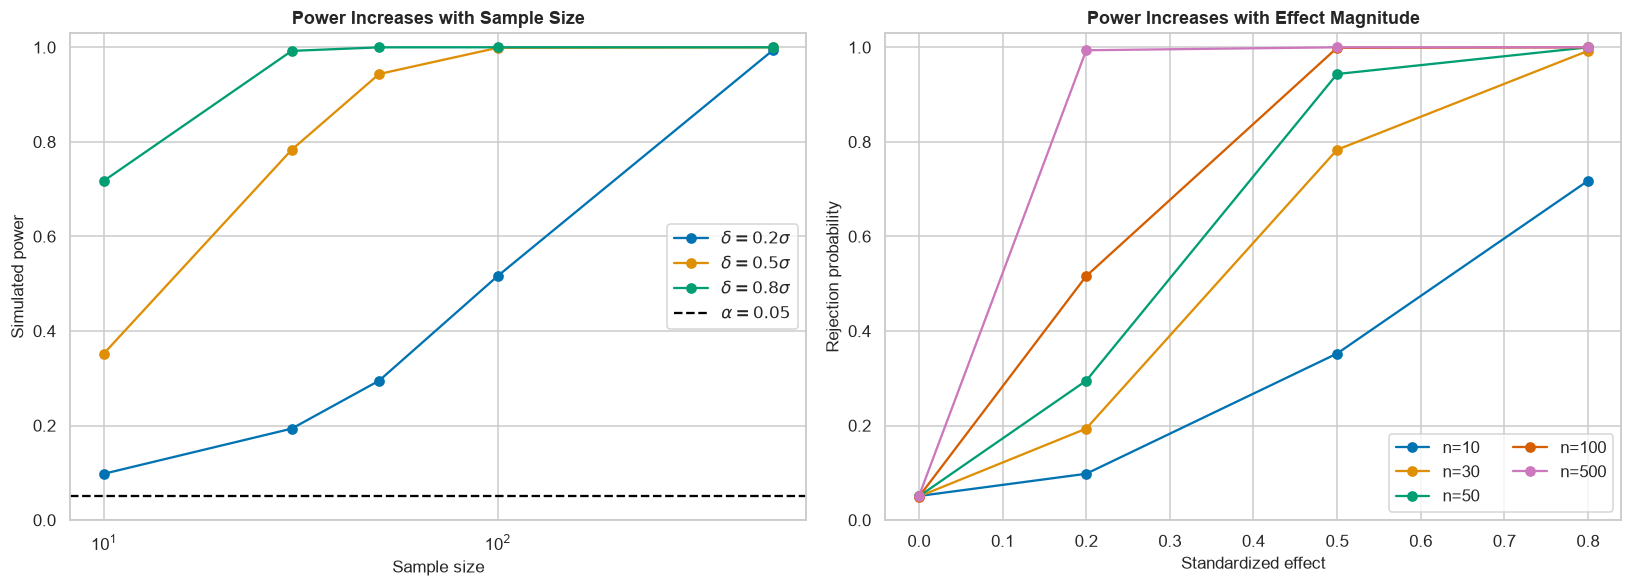

In [6]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for effect in effect_sizes[1:]:
    subset = power_results[power_results["standardized_effect"].eq(effect)]
    axes[0].plot(subset["sample_size"], subset["simulated_rejection_rate"], marker="o", label=rf"$\delta={effect}\sigma$")
axes[0].axhline(alpha, color="black", linestyle="--", label=r"$\alpha=0.05$")
axes[0].set(title="Power Increases with Sample Size", xlabel="Sample size", ylabel="Simulated power", xscale="log", ylim=(0, 1.03))
axes[0].legend()
for n in sample_sizes:
    subset = power_results[power_results["sample_size"].eq(n)]
    axes[1].plot(subset["standardized_effect"], subset["simulated_rejection_rate"], marker="o", label=f"n={n}")
axes[1].set(title="Power Increases with Effect Magnitude", xlabel="Standardized effect", ylabel="Rejection probability", ylim=(0, 1.03))
axes[1].legend(ncol=2)
plt.tight_layout()
plt.show()

### Simulation interpretation

Under the null, rejection rates should fluctuate near $\alpha=0.05$: these are
false positives. Under nonzero effects, non-rejection is a false negative and the
rejection rate estimates power. Larger samples shrink $\sigma/\sqrt n$; larger
effects increase null–alternative separation. Power is conditional on an effect
and assumptions, not a permanent property of a test. Raising alpha usually raises
power but permits more Type I errors. Business costs should guide the trade-off.

# 6. Sampling distributions from the development empirical distribution

For $n\in\{10,30,50,100,500\}$, 3,000 samples are drawn with replacement. For a mean,

$$SE_{\bar X}=\frac{\sigma_{empirical}}{\sqrt n}.$$

For churn proportion,

$$SE_{\hat p}=\sqrt{\frac{p_{empirical}(1-p_{empirical})}{n}}.$$

Source variance uses `ddof=0` because the development empirical distribution is the
complete resampling source. Empirical SE uses `ddof=1` across simulated statistics.
This illustrates conditional sampling variability, not real-world representativeness.

In [7]:
# ruff: noqa: E501
resampling_repetitions = 3_000
sampling_sizes = [10, 30, 50, 100, 500]
resampling_variables = {
    "MonthlyCharges mean": df["MonthlyCharges"].to_numpy(dtype=float),
    "tenure mean": df["tenure"].to_numpy(dtype=float),
    "TotalCharges mean": df["TotalCharges"].to_numpy(dtype=float),
    "churn proportion": df[target_column].eq("Yes").to_numpy(dtype=float),
}
sampling_distributions, sampling_rows = {}, []
for estimator, values in resampling_variables.items():
    source_value, source_sd = values.mean(), values.std(ddof=0)
    for n in sampling_sizes:
        sample_statistics = rng.choice(values, size=(resampling_repetitions, n), replace=True).mean(axis=1)
        sampling_distributions[(estimator, n)] = sample_statistics
        theoretical_se = np.sqrt(source_value * (1 - source_value) / n) if estimator == "churn proportion" else source_sd / np.sqrt(n)
        empirical_se = sample_statistics.std(ddof=1)
        sampling_rows.append({"estimator": estimator, "sample_size": n, "empirical_source_value": source_value, "sampling_distribution_mean": sample_statistics.mean(), "mean_minus_source": sample_statistics.mean() - source_value, "theoretical_standard_error": theoretical_se, "empirical_standard_error": empirical_se, "empirical_minus_theoretical_se": empirical_se - theoretical_se, "sampling_distribution_skewness": stats.skew(sample_statistics, bias=False)})
sampling_summary = pd.DataFrame(sampling_rows)
display(sampling_summary)

,estimator,sample_size,empirical_source_value,sampling_distribution_mean,mean_minus_source,theoretical_standard_error,empirical_standard_error,empirical_minus_theoretical_se,sampling_distribution_skewness
0,MonthlyCharges mean,10,65.032677,65.239412,0.206735,9.493311,9.456794,-0.036518,-0.107448
1,MonthlyCharges mean,30,65.032677,64.971899,-0.060778,5.480966,5.526629,0.045664,-0.044441
2,MonthlyCharges mean,50,65.032677,65.038178,0.005501,4.245538,4.184382,-0.061156,-0.015545
3,MonthlyCharges mean,100,65.032677,65.074842,0.042165,3.002049,3.074605,0.072556,-0.045414
4,MonthlyCharges mean,500,65.032677,65.075251,0.042575,1.342557,1.356516,0.013959,0.013628
5,tenure mean,10,32.349663,32.313333,-0.036329,7.773024,7.739747,-0.033277,0.134970
6,tenure mean,30,32.349663,32.436056,0.086393,4.487757,4.555205,0.067447,0.028927
7,tenure mean,50,32.349663,32.349487,-0.000176,3.476202,3.433550,-0.042652,0.063846
8,tenure mean,100,32.349663,32.344963,-0.004699,2.458046,2.467448,0.009402,0.073898
9,tenure mean,500,32.349663,32.374144,0.024481,1.099272,1.107641,0.008369,0.019564


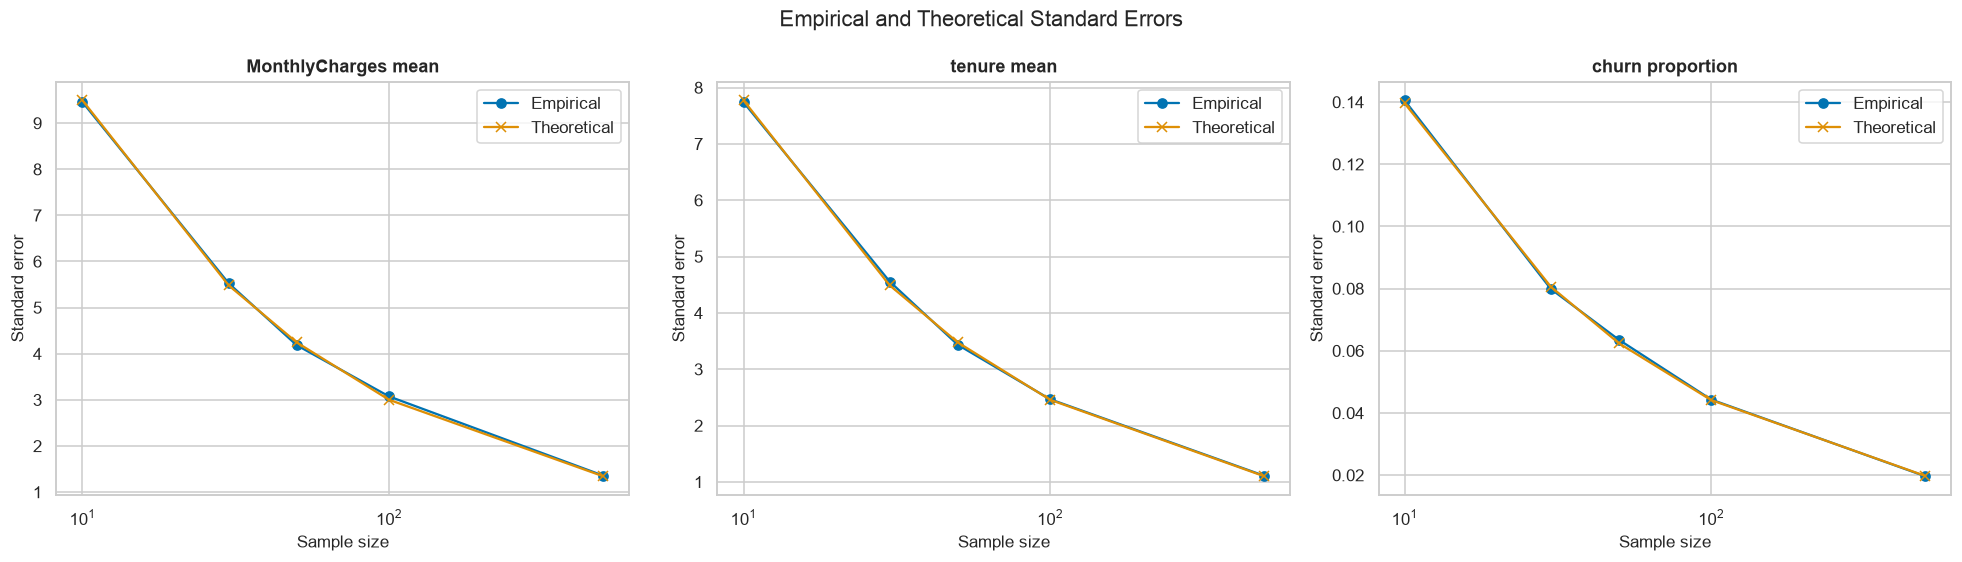

In [8]:
# ruff: noqa: E501
fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))
for axis, estimator in zip(axes, ["MonthlyCharges mean", "tenure mean", "churn proportion"], strict=True):
    subset = sampling_summary[sampling_summary["estimator"].eq(estimator)]
    axis.plot(subset["sample_size"], subset["empirical_standard_error"], marker="o", label="Empirical")
    axis.plot(subset["sample_size"], subset["theoretical_standard_error"], marker="x", label="Theoretical")
    axis.set(title=estimator, xlabel="Sample size", ylabel="Standard error", xscale="log")
    axis.legend()
fig.suptitle("Empirical and Theoretical Standard Errors")
plt.tight_layout()
plt.show()

### Sampling-distribution interpretation

Distribution means should be close to empirical-source values; differences are
Monte Carlo noise, not telecom effects. SE decreases approximately as $1/\sqrt n$,
so quadrupling sample size roughly halves SE. Empirical and theoretical values do
not match exactly because only 3,000 repetitions are used. Real probability
sampling without replacement may require a finite-population correction; this
with-replacement demonstration intentionally does not use one.

# 7. Central Limit Theorem

For IID observations with finite mean $\mu$ and variance $\sigma^2$,

$$\frac{\bar X_n-\mu}{\sigma/\sqrt n}\xrightarrow{d}N(0,1).$$

The theorem concerns the sampling distribution of a standardized mean—not
individual customers. Raw `TotalCharges` remains right-skewed. Convergence depends
on skewness, tails, discreteness, dependence, and finite variance; $n=30$ is a
heuristic, not a guarantee.

**Intuition:** averaging combines deviations and stabilizes an estimator.
**Assumptions:** independence (or a valid generalization), identical distribution
for the classical form, and finite variance. **Telecom example:** repeated samples'
average accumulated charge can be approximately normal while individual charges
are skewed. **Misconception:** CLT does not normalize raw data or repair bias.
**ML relevance:** it can motivate uncertainty for average metrics, but dependence
and repeated selection invalidate naive formulas.

In [9]:
# ruff: noqa: E501
features = ["tenure", "MonthlyCharges", "TotalCharges"]
original_shape = pd.DataFrame({"feature": features, "observation_skewness": [stats.skew(df[x], bias=False) for x in features], "observation_sd_ddof0": [df[x].std(ddof=0) for x in features]}).set_index("feature")
clt_rows = []
for feature in features:
    for n in sampling_sizes:
        means = sampling_distributions[(f"{feature} mean", n)]
        theoretical_se = df[feature].std(ddof=0) / np.sqrt(n)
        empirical_se = means.std(ddof=1)
        clt_rows.append({"feature": feature, "sample_size": n, "original_skewness": original_shape.loc[feature, "observation_skewness"], "sampling_mean_skewness": stats.skew(means, bias=False), "theoretical_se": theoretical_se, "empirical_se": empirical_se, "se_difference": empirical_se - theoretical_se})
clt_summary = pd.DataFrame(clt_rows)
display(original_shape)
display(clt_summary)

,observation_skewness,observation_sd_ddof0
feature,,
tenure,0.240564,24.580460
MonthlyCharges,-0.235174,30.020486
TotalCharges,0.961554,"2,276.954344"


,feature,sample_size,original_skewness,sampling_mean_skewness,theoretical_se,empirical_se,se_difference
0,tenure,10,0.240564,0.134970,7.773024,7.739747,-0.033277
1,tenure,30,0.240564,0.028927,4.487757,4.555205,0.067447
2,tenure,50,0.240564,0.063846,3.476202,3.433550,-0.042652
3,tenure,100,0.240564,0.073898,2.458046,2.467448,0.009402
4,tenure,500,0.240564,0.019564,1.099272,1.107641,0.008369
5,MonthlyCharges,10,-0.235174,-0.107448,9.493311,9.456794,-0.036518
6,MonthlyCharges,30,-0.235174,-0.044441,5.480966,5.526629,0.045664
7,MonthlyCharges,50,-0.235174,-0.015545,4.245538,4.184382,-0.061156
8,MonthlyCharges,100,-0.235174,-0.045414,3.002049,3.074605,0.072556
9,MonthlyCharges,500,-0.235174,0.013628,1.342557,1.356516,0.013959


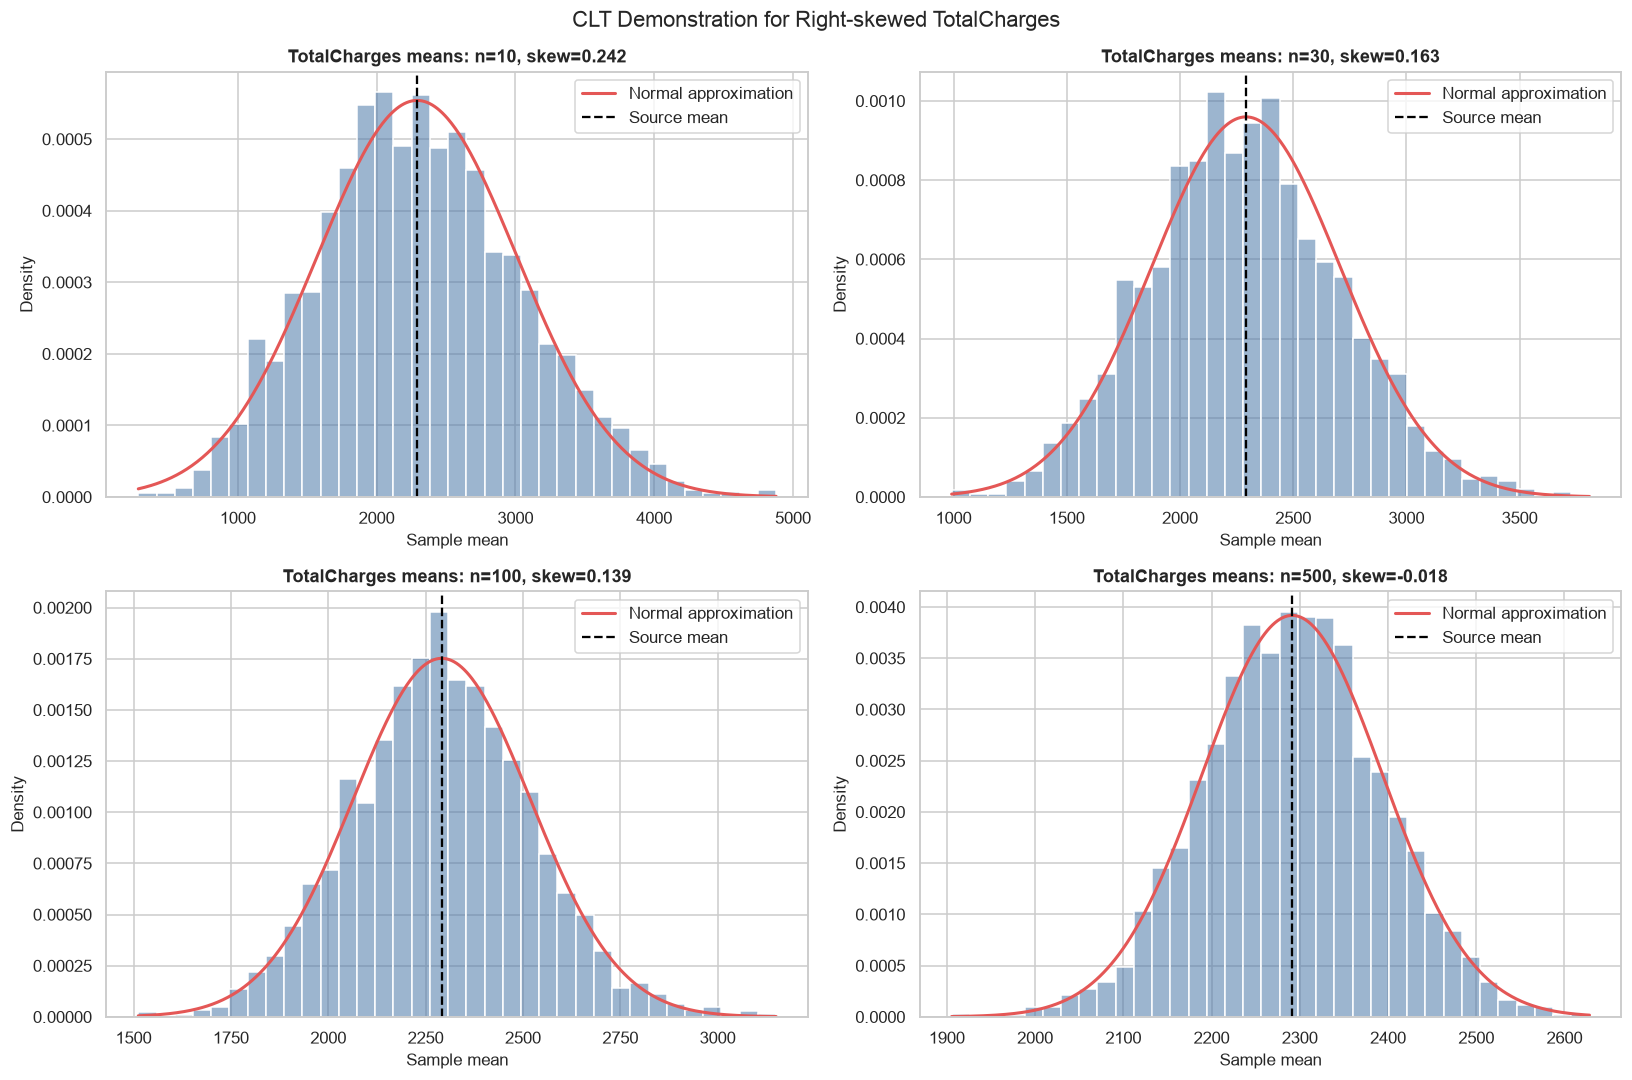

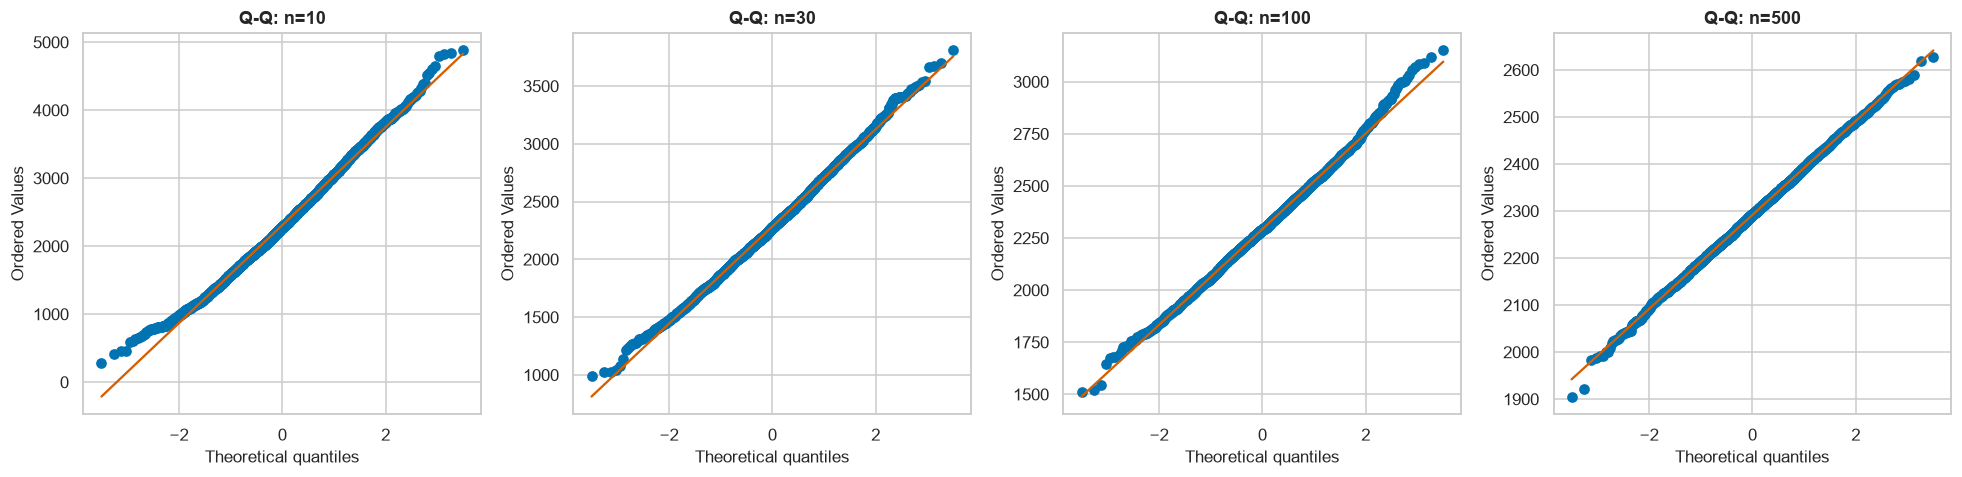

In [10]:
# ruff: noqa: E501
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
total_mean, total_sd = df["TotalCharges"].mean(), df["TotalCharges"].std(ddof=0)
for axis, n in zip(axes.flat, [10, 30, 100, 500], strict=True):
    values = sampling_distributions[("TotalCharges mean", n)]
    sns.histplot(values, bins=35, stat="density", color="#4C78A8", alpha=0.55, ax=axis)
    x = np.linspace(values.min(), values.max(), 500)
    axis.plot(x, stats.norm.pdf(x, total_mean, total_sd / np.sqrt(n)), color="#E45756", linewidth=2, label="Normal approximation")
    axis.axvline(total_mean, color="black", linestyle="--", label="Source mean")
    axis.set(title=f"TotalCharges means: n={n}, skew={stats.skew(values, bias=False):.3f}", xlabel="Sample mean", ylabel="Density")
    axis.legend()
fig.suptitle("CLT Demonstration for Right-skewed TotalCharges")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for axis, n in zip(axes, [10, 30, 100, 500], strict=True):
    stats.probplot(sampling_distributions[("TotalCharges mean", n)], dist="norm", plot=axis)
    axis.set_title(f"Q-Q: n={n}")
plt.tight_layout()
plt.show()

### CLT interpretation

As sample size increases, `TotalCharges` mean distributions generally become less
skewed, concentrate around the source mean, and align more closely with normal and
Q-Q references. The original distribution does not become normal. `tenure` is
discrete and bounded; `MonthlyCharges` has product-mix structure, so their
convergence rates differ. Method choice should reflect the estimand and shape—not
invoke n=30 mechanically.

# 8. Standard deviation versus standard error

**SD** measures observation-level dispersion:

$$\sigma=\sqrt{\mathbb{E}[(X-\mu)^2]}.$$

**SE** measures estimator-level dispersion:

$$SE(\bar X)=\frac{\sigma}{\sqrt n},\qquad
SE(\hat p)=\sqrt{\frac{p(1-p)}{n}}.$$

SD need not shrink as more customers are collected; SE shrinks because an average
or proportion becomes more precise. Source SD uses `ddof=0`; simulated-distribution
SD uses `ddof=1`. **Telecom example:** MonthlyCharges remain heterogeneous while
uncertainty in their mean falls. **Misconception:** SE is not customer variability.
**ML relevance:** per-customer error dispersion and uncertainty in mean model
performance answer different questions.

,estimator,sample_size,empirical_source_value,sampling_distribution_mean,mean_minus_source,theoretical_standard_error,empirical_standard_error,empirical_minus_theoretical_se,sampling_distribution_skewness,observation_level_sd_ddof0
0,MonthlyCharges mean,10,65.032677,65.239412,0.206735,9.493311,9.456794,-0.036518,-0.107448,30.020486
1,MonthlyCharges mean,30,65.032677,64.971899,-0.060778,5.480966,5.526629,0.045664,-0.044441,30.020486
2,MonthlyCharges mean,50,65.032677,65.038178,0.005501,4.245538,4.184382,-0.061156,-0.015545,30.020486
3,MonthlyCharges mean,100,65.032677,65.074842,0.042165,3.002049,3.074605,0.072556,-0.045414,30.020486
4,MonthlyCharges mean,500,65.032677,65.075251,0.042575,1.342557,1.356516,0.013959,0.013628,30.020486
5,tenure mean,10,32.349663,32.313333,-0.036329,7.773024,7.739747,-0.033277,0.134970,24.580460
6,tenure mean,30,32.349663,32.436056,0.086393,4.487757,4.555205,0.067447,0.028927,24.580460
7,tenure mean,50,32.349663,32.349487,-0.000176,3.476202,3.433550,-0.042652,0.063846,24.580460
8,tenure mean,100,32.349663,32.344963,-0.004699,2.458046,2.467448,0.009402,0.073898,24.580460
9,tenure mean,500,32.349663,32.374144,0.024481,1.099272,1.107641,0.008369,0.019564,24.580460


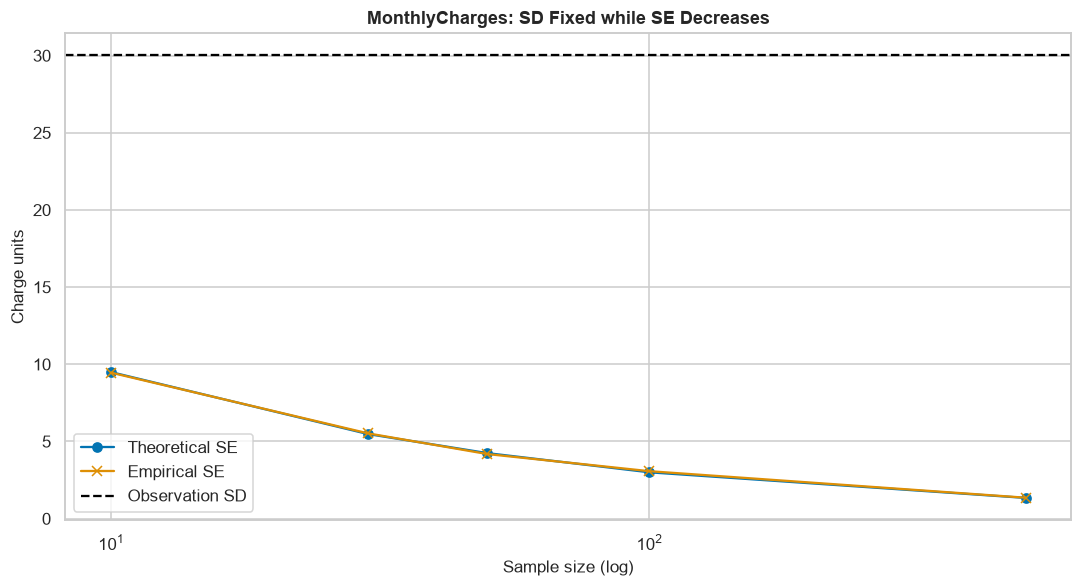

In [11]:
# ruff: noqa: E501
sd_se_table = sampling_summary[sampling_summary["estimator"].isin(["MonthlyCharges mean", "tenure mean", "churn proportion"])].copy()
sd_lookup = {"MonthlyCharges mean": df["MonthlyCharges"].std(ddof=0), "tenure mean": df["tenure"].std(ddof=0), "churn proportion": df[target_column].eq("Yes").std(ddof=0)}
sd_se_table["observation_level_sd_ddof0"] = sd_se_table["estimator"].map(sd_lookup)
display(sd_se_table)
monthly = sd_se_table[sd_se_table["estimator"].eq("MonthlyCharges mean")]
fig, axis = plt.subplots(figsize=(10, 5.5))
axis.plot(monthly["sample_size"], monthly["theoretical_standard_error"], marker="o", label="Theoretical SE")
axis.plot(monthly["sample_size"], monthly["empirical_standard_error"], marker="x", label="Empirical SE")
axis.axhline(sd_lookup["MonthlyCharges mean"], color="black", linestyle="--", label="Observation SD")
axis.set(title="MonthlyCharges: SD Fixed while SE Decreases", xlabel="Sample size (log)", ylabel="Charge units", xscale="log")
axis.legend()
plt.tight_layout()
plt.show()

# 9. Interview questions and speakable answers

### Q1. What does the CLT say, and what does it not say?

**Answer:** For IID observations with finite variance, the standardized sample mean
approaches a normal distribution as sample size grows. It concerns the estimator
across samples, not individual observations. Convergence depends on the source, so
n=30 is not universal. In ML it may justify uncertainty approximations for average
metrics, but dependence, heavy tails, and repeated selection can invalidate them.

### Q2. How are SD and SE different?

**Answer:** SD describes variation among observations. SE describes how an estimator
would vary across repeated samples. For an IID mean, $SE=\sigma/\sqrt n$. More data
reduces SE but not necessarily customer SD. I report SD for heterogeneity and SE or
an interval for estimate precision.

### Q3. Explain Type I error, Type II error, and power.

**Answer:** Type I error rejects a true null and is controlled by alpha under valid
assumptions. Type II error fails to reject a false null. Power is one minus Type II
error for a specified effect. Power rises with sample size, effect magnitude, lower
noise, and often relaxed alpha—though relaxed alpha increases false positives.

### Q4. Why is statistical significance not practical significance?

**Answer:** Statistical significance measures incompatibility with a null and
depends strongly on sample size. Practical significance asks whether magnitude
matters operationally. A tiny charge difference may be highly significant yet not
cover campaign costs. I report raw and standardized effect, uncertainty, support,
and a business threshold—not only a p-value.

# 10. Assumptions and limits

1. Development rows are an empirical resampling source; representativeness is unknown.
2. Resampling assumes independent draws with replacement from that distribution.
3. Theoretical mean SE uses empirical `ddof=0`; empirical SE uses `ddof=1`.
4. Synthetic power assumes normal estimators, known variance, two-sided alpha 0.05.
5. The hypothesis register is EDA-informed; no telecom p-values are calculated.
6. Observational associations may reflect confounding, selection, and measurement.
7. No confidence intervals, formal telecom tests, feature engineering, selection,
   balancing, preprocessing, or predictive models are produced.

## 11. Reproducibility and leakage verification

The final cell checks the configured input, development checksum, seven prior
notebook hashes, and simulation invariants. Held-out and validated observations are
never loaded.

In [12]:
# ruff: noqa: E501
expected_previous_hashes = {
    "01_exploratory_data_analysis.ipynb": "970288d8018d13770f972835b4ecc86fe7857e28c0b7447b104fa5b3edcf662b",
    "02_univariate_analysis.ipynb": "0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8edef76e26d61b851de4a",
    "03_bivariate_analysis.ipynb": "1ec80ddc2eb412b604841a20afa78e5199903ff00206f4e291a48a16d655d495",
    "04_multivariate_analysis.ipynb": "4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0ff01afbe3d596573331",
    "05_correlation_association_analysis.ipynb": "e787e951b3443c6052d960b384d5418c7c13e2e846c6d7e3a15f7895cd7faa13",
    "06_outlier_anomaly_analysis.ipynb": "f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece57da2f74d9eb3e1ef4b",
    "07_customer_segmentation_business_analysis.ipynb": "1dee5509dc803187d99bb61af9d2eefc272f8a83c9d1014409f35834ca35cf6d",
}
observed_previous_hashes = {name: hashlib.sha256((PROJECT_ROOT / "notebooks" / name).read_bytes()).hexdigest() for name in expected_previous_hashes}
source_sha256_after = hashlib.sha256(development_path.read_bytes()).hexdigest()

assert observed_previous_hashes == expected_previous_hashes
assert source_sha256_before == source_sha256_after == "28d12b92122ab94a8172be83e2bcf7e93b128a1bf3633c2b48075c426864da13"
assert development_path.name == "development.parquet"
assert development_path != (PROJECT_ROOT / config["data"]["test_path"]).resolve()
assert development_path != (PROJECT_ROOT / config["data"]["validated_path"]).resolve()
assert random_state == 42
assert len(hypothesis_register) == 10
assert set(sampling_summary["sample_size"]) == set(sampling_sizes)
assert abs(false_positive_rate - alpha) < 0.01
assert power_results["absolute_difference"].max() < 0.015
assert sampling_summary["empirical_standard_error"].gt(0).all()
assert sampling_summary["theoretical_standard_error"].gt(0).all()

print("All statistical-foundation verification checks passed.")
print("Loaded data source:", development_path.relative_to(PROJECT_ROOT))
print("Held-out test and complete validated datasets were not accessed.")
display(pd.DataFrame({"expected_sha256": expected_previous_hashes, "observed_sha256": observed_previous_hashes}))

All statistical-foundation verification checks passed.
Loaded data source: data/processed/development.parquet
Held-out test and complete validated datasets were not accessed.


,expected_sha256,observed_sha256
01_exploratory_data_analysis.ipynb,970288d8018d13770f972835b4ecc86fe7857e28c0b744...,970288d8018d13770f972835b4ecc86fe7857e28c0b744...
02_univariate_analysis.ipynb,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...,0fb866bc140e43c42372e7c13af8712d78ab5b0f49d8ed...
03_bivariate_analysis.ipynb,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...,1ec80ddc2eb412b604841a20afa78e5199903ff00206f4...
04_multivariate_analysis.ipynb,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...,4bc0c85cdc2f8314b4d68ef1954e7b4c03b44902137b0f...
05_correlation_association_analysis.ipynb,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...,e787e951b3443c6052d960b384d5418c7c13e2e846c6d7...
06_outlier_anomaly_analysis.ipynb,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...,f75450ecf0576bd49f35e864f2c5b8f389ac020b35ece5...
07_customer_segmentation_business_analysis.ipynb,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...,1dee5509dc803187d99bb61af9d2eefc272f8a83c9d101...


# Conclusion

This notebook established inferential language, assumptions, error-rate and power
intuition, empirical sampling distributions, the CLT, and standard errors. It stops
before confidence intervals and formal telecom hypothesis testing.